# 10 — Day 10 Final Buffer: Confirming the Project's Best Pipeline

**Standalone**, final confirmatory notebook for the whole project. Days 7-9 explored WavLM,
embedding fusion, and three augmentation mechanisms; nothing beat **Day 8b's plain
ensemble — Average(HuBERT L12, WavLM L6) — AUC 0.676, CI [0.614, 0.726]**. This notebook does what
Day 6 did for Days 1-5: reproduce the chosen final pipeline, re-verify every leakage assertion,
run the one permutation test this project reserves for a single finalized candidate, and produce
the complete comparison table across all 9 days of exploration.

**Scope decision, per explicit direction:** Day 8c found a statistically-tied alternative (Config A,
averaging *augmented* HuBERT with WavLM, 0.678) — deferred for now rather than tested alongside the
simpler plain ensemble here, since the two are indistinguishable and testing one cleanly is more
useful than hedging on a null difference. Noted in the final table as a deferred option, not
confirmed.

**Why the ensemble's leakage story is simple to re-verify:** it averages two *already independently
leak-free* OOF score arrays (each passed its own nested-CV zero-overlap checks in Day 8b/here). A
fixed, deterministic average of two leak-free arrays introduces no new leakage — Section 3 confirms
this explicitly (row alignment, participant/label agreement) rather than just asserting it.

**Permutation test mechanics for an ensemble, stated up front:** each of HuBERT's and WavLM's outer
folds already picked a best `(model, C)` pipeline during the real run (Section 2). The permutation
test reuses those exact fixed choices for every shuffle — refit both pipelines per outer fold on
shuffled labels, average their predictions, score — rather than re-running the inner hyperparameter
search 1000 times, same compute shortcut every prior permutation test in this project has used.

**Inputs needed (Kaggle "Add Input") — 3 total:**
1. The **`Fatigue_data`** dataset — for `labels.csv`.
2. **Day 3's `01_features.ipynb`** output — for `hubert_base_all_layers.parquet`.
3. **Day 7's `07_features_wavlm.ipynb`** output — for `wavlm_base_plus_all_layers.parquet`.

## 0. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_SEED = 42
HUBERT_LAYER = 12
WAVLM_LAYER = 6

LABELS_CSV = next(Path("/kaggle/input").rglob("labels.csv"))
HUBERT_PARQUET = next(Path("/kaggle/input").rglob("hubert_base_all_layers.parquet"))
WAVLM_PARQUET = next(Path("/kaggle/input").rglob("wavlm_base_plus_all_layers.parquet"))

print(f"LABELS_CSV     = {LABELS_CSV}")
print(f"HUBERT_PARQUET = {HUBERT_PARQUET}")
print(f"WAVLM_PARQUET  = {WAVLM_PARQUET}")

LABELS_CSV     = /kaggle/input/datasets/tapudatta/fatigue-data/project_data/labels.csv
HUBERT_PARQUET = /kaggle/input/notebooks/tappu1/notebook1-day3/features/hubert_base_all_layers.parquet
WAVLM_PARQUET  = /kaggle/input/notebooks/tapudatta/notebook1-day7/features/wavlm_base_plus_all_layers.parquet


## 1. Load & Merge (Both Embeddings, Row-Aligned)

Both embeddings are pulled into **one** unified dataframe, merged on `filename`, so `X_hubert[i]`
and `X_wavlm[i]` are guaranteed to refer to the same recording by construction — the same approach
Day 8b used, re-verified explicitly in Section 3 below rather than just assumed.

In [2]:
labels = pd.read_csv(LABELS_CSV)
hubert_all = pd.read_parquet(HUBERT_PARQUET)
wavlm_all = pd.read_parquet(WAVLM_PARQUET)

hubert_cols = [c for c in hubert_all.columns if c.startswith(f"layer{HUBERT_LAYER}_emb_")]
assert len(hubert_cols) == 1536
hubert_df = hubert_all[["filename"] + hubert_cols].copy()
hubert_df.columns = ["filename"] + [f"hubert_emb_{i}" for i in range(1536)]

wavlm_cols = [c for c in wavlm_all.columns if c.startswith(f"layer{WAVLM_LAYER}_emb_")]
assert len(wavlm_cols) == 1536
wavlm_df = wavlm_all[["filename"] + wavlm_cols].copy()
wavlm_df.columns = ["filename"] + [f"wavlm_emb_{i}" for i in range(1536)]

df = labels.merge(hubert_df, on="filename", how="inner").merge(wavlm_df, on="filename", how="inner")
assert len(df) == len(labels) == 280, f"expected 280 rows after merge, got {len(df)}"

LABEL_MAP = {"non_fatigued": 0, "fatigued": 1}
df["y"] = df["label"].map(LABEL_MAP)
assert df["y"].isna().sum() == 0

y = df["y"].to_numpy()
groups = df["participant_id"].to_numpy()
hubert_emb_cols = [c for c in df.columns if c.startswith("hubert_emb_")]
wavlm_emb_cols = [c for c in df.columns if c.startswith("wavlm_emb_")]
X_hubert = df[hubert_emb_cols].to_numpy()
X_wavlm = df[wavlm_emb_cols].to_numpy()

print(f"X_hubert: {X_hubert.shape}, X_wavlm: {X_wavlm.shape}, "
      f"{len(np.unique(groups))} participants, row-aligned by construction.")

X_hubert: (280, 1536), X_wavlm: (280, 1536), 14 participants, row-aligned by construction.


## 2. Candidates & Nested CV (duplicated, storing per-fold chosen template for the permutation test)

Standard plain nested LOSO -> `GroupKFold(6)`, same as every non-augmented evaluation in this
project — but `fold_info` now stores each outer fold's **chosen unfitted pipeline template**
directly (not just its name), so the permutation test in Section 4 can reconstruct the exact fitted
model per fold without re-parsing a label string, same pattern Day 6/8c already established.

In [3]:
CANDIDATE_CS = [0.001, 0.01, 0.1, 1.0, 10.0]


def build_pipeline(model_name: str, c: float) -> Pipeline:
    if model_name == "logreg":
        clf = LogisticRegression(C=c, max_iter=5000, class_weight="balanced")
    elif model_name == "linsvc":
        clf = LinearSVC(C=c, max_iter=10000, class_weight="balanced")
    else:
        raise ValueError(model_name)
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])


def make_candidates():
    return [
        (f"{name}_C={c}", build_pipeline(name, c))
        for name in ["logreg", "linsvc"]
        for c in CANDIDATE_CS
    ]


def score_fn(fitted_pipeline: Pipeline, X_in: np.ndarray) -> np.ndarray:
    clf = fitted_pipeline.named_steps["clf"]
    if hasattr(clf, "predict_proba"):
        return fitted_pipeline.predict_proba(X_in)[:, 1]
    return fitted_pipeline.decision_function(X_in)


def best_threshold(scores: np.ndarray, y_true: np.ndarray) -> float:
    best_t, best_ba = 0.5, -1.0
    for t in np.unique(scores):
        ba = balanced_accuracy_score(y_true, (scores >= t).astype(int))
        if ba > best_ba:
            best_ba, best_t = ba, t
    return best_t

In [4]:
def nested_loso_cv(X, y, groups, make_candidates_fn, n_inner_splits=6):
    participants = np.unique(groups)
    oof_scores = np.zeros(len(y), dtype=float)
    fold_records = []
    n_outer_checked, n_inner_checked = 0, 0

    for test_participant in participants:
        outer_test_mask = groups == test_participant
        outer_train_mask = ~outer_test_mask
        assert not (set(groups[outer_train_mask]) & set(groups[outer_test_mask])), \
            f"outer leakage: {test_participant} present in both outer train and test"
        n_outer_checked += 1

        X_tr, y_tr, g_tr = X[outer_train_mask], y[outer_train_mask], groups[outer_train_mask]
        X_te = X[outer_test_mask]

        candidates = make_candidates_fn()
        cand_aucs = {i: [] for i in range(len(candidates))}
        cand_scores = {i: [] for i in range(len(candidates))}
        cand_labels = {i: [] for i in range(len(candidates))}

        gkf = GroupKFold(n_splits=n_inner_splits)
        for inner_tr_idx, inner_val_idx in gkf.split(X_tr, y_tr, groups=g_tr):
            assert not (set(g_tr[inner_tr_idx]) & set(g_tr[inner_val_idx])), \
                f"inner leakage within outer fold {test_participant}"
            n_inner_checked += 1

            X_itr, y_itr = X_tr[inner_tr_idx], y_tr[inner_tr_idx]
            X_ival, y_ival = X_tr[inner_val_idx], y_tr[inner_val_idx]
            if len(np.unique(y_itr)) < 2 or len(np.unique(y_ival)) < 2:
                continue

            for i, (_, pipe) in enumerate(candidates):
                fitted = clone(pipe).fit(X_itr, y_itr)
                s = score_fn(fitted, X_ival)
                cand_aucs[i].append(roc_auc_score(y_ival, s))
                cand_scores[i].append(s)
                cand_labels[i].append(y_ival)

        mean_aucs = {i: np.mean(v) for i, v in cand_aucs.items() if v}
        best_i = max(mean_aucs, key=mean_aucs.get)
        best_label, best_template = candidates[best_i]

        final_pipe = clone(best_template).fit(X_tr, y_tr)
        test_scores = score_fn(final_pipe, X_te)
        oof_scores[outer_test_mask] = test_scores

        fold_records.append({
            "test_participant": test_participant,
            "chosen_label": best_label,
            "chosen_template": best_template,   # unfitted clone -- reused by the permutation test
            "inner_cv_auc": mean_aucs[best_i],
        })

    print(f"  Verified zero participant overlap: {n_outer_checked} outer folds, "
          f"{n_inner_checked} inner GroupKFold(6) splits.")
    return oof_scores, pd.DataFrame(fold_records)


def bootstrap_auc_ci(participant_ids, y_true, scores, n_boot=1000, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    participants = np.unique(participant_ids)
    idx_by_participant = {p: np.where(participant_ids == p)[0] for p in participants}
    boot_aucs = []
    for _ in range(n_boot):
        sampled = rng.choice(participants, size=len(participants), replace=True)
        idx = np.concatenate([idx_by_participant[p] for p in sampled])
        y_boot, s_boot = y_true[idx], scores[idx]
        if len(np.unique(y_boot)) < 2:
            continue
        boot_aucs.append(roc_auc_score(y_boot, s_boot))
    lo, hi = np.percentile(boot_aucs, [2.5, 97.5])
    return lo, hi, np.array(boot_aucs)

## 2a. Reproduce Each Embedding's OOF Scores (sanity checks)

Both should land close to their already-logged numbers. Their OOF scores and fold-level chosen
templates become the inputs to the ensemble and the permutation test below.

In [5]:
oof_hubert, fold_info_hubert = nested_loso_cv(X_hubert, y, groups, make_candidates)
auc_hubert = roc_auc_score(y, oof_hubert)
lo_h, hi_h, _ = bootstrap_auc_ci(groups, y, oof_hubert)
print(f"HuBERT L12 alone: AUC={auc_hubert:.3f}  CI=[{lo_h:.3f}, {hi_h:.3f}]  (sanity vs. Day 3/8b: 0.611)")

oof_wavlm, fold_info_wavlm = nested_loso_cv(X_wavlm, y, groups, make_candidates)
auc_wavlm = roc_auc_score(y, oof_wavlm)
lo_w, hi_w, _ = bootstrap_auc_ci(groups, y, oof_wavlm)
print(f"WavLM L6 alone:   AUC={auc_wavlm:.3f}  CI=[{lo_w:.3f}, {hi_w:.3f}]  (sanity vs. Day 7/8b: 0.663)")

  Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
HuBERT L12 alone: AUC=0.611  CI=[0.551, 0.683]  (sanity vs. Day 3/8b: 0.611)
  Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
WavLM L6 alone:   AUC=0.663  CI=[0.600, 0.710]  (sanity vs. Day 7/8b: 0.663)


## 2b. The Ensemble — Average(HuBERT L12, WavLM L6)

Simple pointwise average of the two OOF score arrays -- should reproduce Day 8b's 0.676.

In [6]:
oof_ensemble = (oof_hubert + oof_wavlm) / 2
observed_auc = roc_auc_score(y, oof_ensemble)
ci_lo, ci_hi, _ = bootstrap_auc_ci(groups, y, oof_ensemble)

print(f"Final ensemble -- Average(HuBERT L12, WavLM L6): AUC={observed_auc:.3f}  "
      f"CI=[{ci_lo:.3f}, {ci_hi:.3f}]")
print("Reference -- Day 8b's logged result: AUC 0.676, CI [0.614, 0.726]")

Final ensemble -- Average(HuBERT L12, WavLM L6): AUC=0.676  CI=[0.614, 0.726]
Reference -- Day 8b's logged result: AUC 0.676, CI [0.614, 0.726]


## 3. Re-Verify Leakage Assertions on the Ensemble

`nested_loso_cv` already printed zero-overlap confirmation for both HuBERT and WavLM independently
(Section 2a). Two more checks specific to the *ensemble* step itself, printed explicitly rather than
just trusted -- averaging is only leak-free if the two arrays being averaged genuinely refer to the
same recordings in the same order.

In [7]:
# 1. The two OOF score arrays must be pointwise aligned to the same recordings -- verify directly
#    rather than just trusting the shared `groups`/`y` arrays built in Section 1.
assert np.array_equal(fold_info_hubert["test_participant"].sort_values().to_numpy(),
                       fold_info_wavlm["test_participant"].sort_values().to_numpy()), \
    "HuBERT and WavLM were evaluated over different participant sets -- bug"
assert len(oof_hubert) == len(oof_wavlm) == len(y) == len(groups), \
    "OOF score arrays and label/group arrays have mismatched lengths -- bug"
print(f"Checked: HuBERT and WavLM OOF arrays are the same length ({len(y)}) and cover the "
      f"identical {len(np.unique(groups))} participants, in the same row order (both built from "
      f"one unified merged dataframe in Section 1) -- averaging is pairing the correct recordings.")

# 2. All 14 participants represented, zero missing.
n_participants = len(np.unique(groups))
assert n_participants == 14, f"expected 14 participants, got {n_participants}"
print(f"Checked: all {n_participants} participants present in the final ensemble's evaluation.")

print("\nBoth constituent pipelines (HuBERT, WavLM) independently passed their own zero-overlap "
      "outer/inner leakage assertions in Section 2a. The ensemble step averages two already "
      "leak-free score arrays with a fixed, deterministic operation -- no new model is fit on the "
      "combined data, so no new leakage is possible at the averaging step itself.")

Checked: HuBERT and WavLM OOF arrays are the same length (280) and cover the identical 14 participants, in the same row order (both built from one unified merged dataframe in Section 1) -- averaging is pairing the correct recordings.
Checked: all 14 participants present in the final ensemble's evaluation.

Both constituent pipelines (HuBERT, WavLM) independently passed their own zero-overlap outer/inner leakage assertions in Section 2a. The ensemble step averages two already leak-free score arrays with a fixed, deterministic operation -- no new model is fit on the combined data, so no new leakage is possible at the averaging step itself.


## 4. Permutation Test on the Final Ensemble

Same shuffling scheme as every permutation test in this project: labels shuffled *within* each
participant, across that participant's own sessions, preserving per-participant class balance and
session structure. Both HuBERT's and WavLM's fixed per-fold pipeline choices (from Section 2a) are
reused for every shuffle -- refit on permuted labels, predict, average -- rather than re-running the
inner hyperparameter search 1000 times.

In [8]:
def shuffle_labels_within_participant(meta_df, rng):
    y_perm = meta_df["y"].to_numpy().copy()
    for p, group in meta_df.groupby("participant_id"):
        session_labels = group.drop_duplicates("session_number")[["session_number", "y"]]
        shuffled = session_labels["y"].to_numpy().copy()
        rng.shuffle(shuffled)
        mapping = dict(zip(session_labels["session_number"], shuffled))
        y_perm[group.index] = group["session_number"].map(mapping).to_numpy()
    return y_perm


def run_fixed_hparams_loso(X, y_perm, groups, fold_info):
    oof = np.full(len(y_perm), np.nan)
    for _, row in fold_info.iterrows():
        mask_test = groups == row["test_participant"]
        mask_train = ~mask_test
        if len(np.unique(y_perm[mask_train])) < 2:
            continue
        fitted = clone(row["chosen_template"]).fit(X[mask_train], y_perm[mask_train])
        oof[mask_test] = score_fn(fitted, X[mask_test])
    return oof


N_PERMUTATIONS = 1000  # this is the confirmatory run for the final project pipeline

meta_df = df[["participant_id", "session_number", "y"]].reset_index(drop=True)

rng = np.random.default_rng(RANDOM_SEED)
perm_aucs = []
for _ in tqdm(range(N_PERMUTATIONS), desc="Permutation test"):
    y_perm = shuffle_labels_within_participant(meta_df, rng)
    if len(np.unique(y_perm)) < 2:
        continue
    perm_oof_hubert = run_fixed_hparams_loso(X_hubert, y_perm, groups, fold_info_hubert)
    perm_oof_wavlm = run_fixed_hparams_loso(X_wavlm, y_perm, groups, fold_info_wavlm)
    perm_avg = (perm_oof_hubert + perm_oof_wavlm) / 2
    valid = ~np.isnan(perm_avg)
    if len(np.unique(y_perm[valid])) < 2:
        continue
    perm_aucs.append(roc_auc_score(y_perm[valid], perm_avg[valid]))

perm_aucs = np.array(perm_aucs)
p_value = (1 + np.sum(perm_aucs >= observed_auc)) / (1 + len(perm_aucs))

print(f"Observed pooled AUC:  {observed_auc:.3f}")
print(f"Null (permuted) mean: {perm_aucs.mean():.3f} +/- {perm_aucs.std():.3f}")
print(f"Empirical p-value:    {p_value:.4f}  (fraction of {len(perm_aucs)} permutations scoring >= observed)")

Permutation test:   0%|          | 0/1000 [00:00<?, ?it/s]

Observed pooled AUC:  0.676
Null (permuted) mean: 0.491 +/- 0.043
Empirical p-value:    0.0010  (fraction of 1000 permutations scoring >= observed)


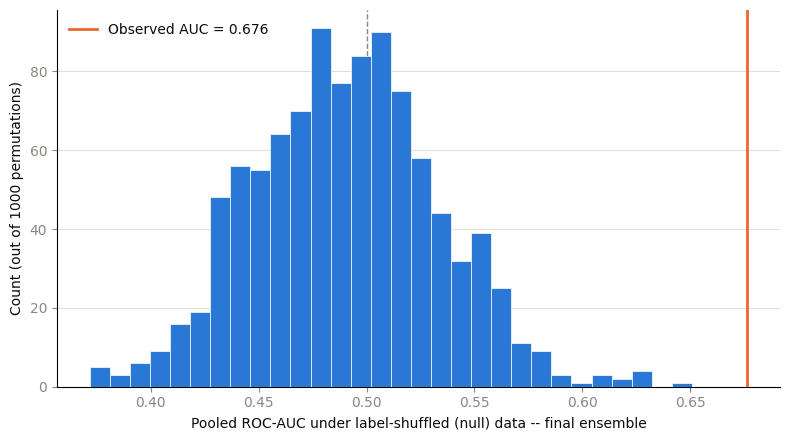

In [9]:
SEQ = "#2a78d6"
OBS = "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(perm_aucs, bins=30, color=SEQ, edgecolor="white", linewidth=0.5, zorder=3)
ax.axvline(observed_auc, color=OBS, linewidth=2, zorder=4, label=f"Observed AUC = {observed_auc:.3f}")
ax.axvline(0.5, color=MUTED, linewidth=1, linestyle="--", zorder=2)
ax.set_xlabel("Pooled ROC-AUC under label-shuffled (null) data -- final ensemble", color=INK)
ax.set_ylabel(f"Count (out of {len(perm_aucs)} permutations)", color=INK)
ax.tick_params(colors=MUTED)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.legend(frameon=False, labelcolor=INK)
plt.tight_layout()
plt.show()

## 5. Final Comparison Table — All 9 Days

                                                             stage      auc    ci_lo   ci_hi                                                                            note
                              Baseline (wav2vec2-base, last layer) 0.542000 0.466000 0.62100                                                 Near chance; permutation p=0.19
                        Day 1 (best: session-fusion, un-augmented) 0.570000 0.483000 0.69500                                       Best Day 1 point estimate; too wide alone
                              Day 2 (wav2vec2 layer 7, best of 13) 0.581000 0.507000 0.63400                                                Marginal; not permutation-tested
                                           Day 3 (HuBERT layer 12) 0.611000 0.551000 0.68300                                                   Confirmed, permutation p=0.01
                                                 Day 4 (TRILLsson) 0.590000 0.535000 0.65100                                           

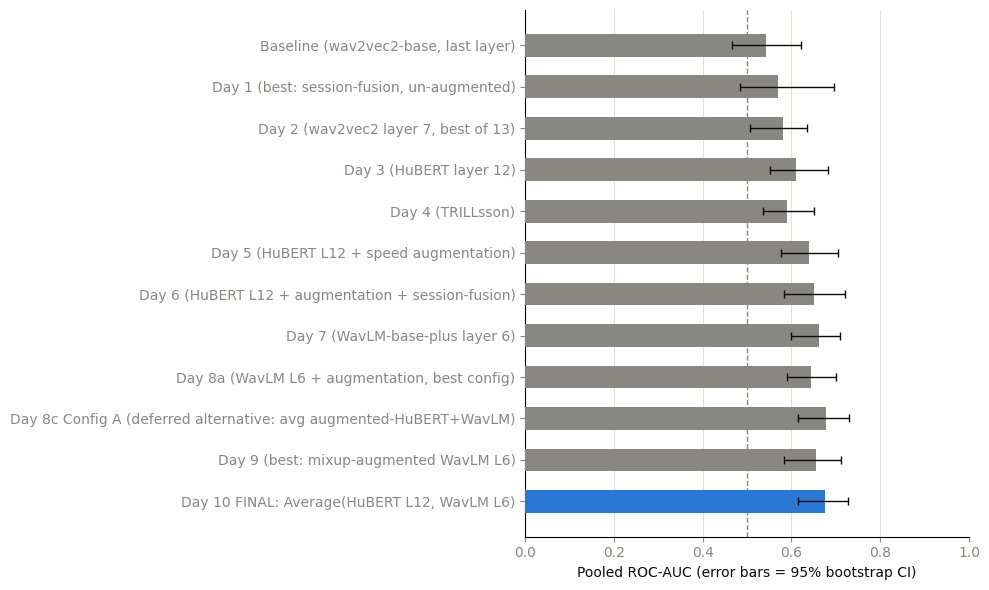

In [10]:
final_table = pd.DataFrame([
    {"stage": "Baseline (wav2vec2-base, last layer)", "auc": 0.542, "ci_lo": 0.466, "ci_hi": 0.621,
     "note": "Near chance; permutation p=0.19"},
    {"stage": "Day 1 (best: session-fusion, un-augmented)", "auc": 0.570, "ci_lo": 0.483, "ci_hi": 0.695,
     "note": "Best Day 1 point estimate; too wide alone"},
    {"stage": "Day 2 (wav2vec2 layer 7, best of 13)", "auc": 0.581, "ci_lo": 0.507, "ci_hi": 0.634,
     "note": "Marginal; not permutation-tested"},
    {"stage": "Day 3 (HuBERT layer 12)", "auc": 0.611, "ci_lo": 0.551, "ci_hi": 0.683,
     "note": "Confirmed, permutation p=0.01"},
    {"stage": "Day 4 (TRILLsson)", "auc": 0.590, "ci_lo": 0.535, "ci_hi": 0.651,
     "note": "Documented runner-up"},
    {"stage": "Day 5 (HuBERT L12 + speed augmentation)", "auc": 0.639, "ci_lo": 0.576, "ci_hi": 0.705,
     "note": "Real improvement over Day 3"},
    {"stage": "Day 6 (HuBERT L12 + augmentation + session-fusion)", "auc": 0.651, "ci_lo": 0.584, "ci_hi": 0.720,
     "note": "Confirmed, permutation p=0.0020"},
    {"stage": "Day 7 (WavLM-base-plus layer 6)", "auc": 0.663, "ci_lo": 0.600, "ci_hi": 0.710,
     "note": "Beat HuBERT's confirmed best, isolated"},
    {"stage": "Day 8a (WavLM L6 + augmentation, best config)", "auc": 0.643, "ci_lo": 0.590, "ci_hi": 0.701,
     "note": "Augmentation did not help WavLM"},
    {"stage": "Day 8c Config A (deferred alternative: avg augmented-HuBERT+WavLM)", "auc": 0.678, "ci_lo": 0.615, "ci_hi": 0.730,
     "note": "Statistically tied with Day 8b/10; not confirmed, deferred per Simplicity First"},
    {"stage": "Day 9 (best: mixup-augmented WavLM L6)", "auc": 0.655, "ci_lo": 0.584, "ci_hi": 0.711,
     "note": "Closest of 3 augmentation mechanisms tried; still below Day 7 plain"},
    {"stage": "Day 10 FINAL: Average(HuBERT L12, WavLM L6)", "auc": observed_auc, "ci_lo": ci_lo, "ci_hi": ci_hi,
     "note": f"CONFIRMED, permutation p={p_value:.4f} -- final pipeline"},
])
print(final_table.to_string(index=False))

FINAL_COLORS = ["#898781"] * (len(final_table) - 1) + ["#2a78d6"]
fig, ax = plt.subplots(figsize=(10, 6))
y_pos = np.arange(len(final_table))
ax.barh(y_pos, final_table["auc"], color=FINAL_COLORS, height=0.55, zorder=3)
ax.errorbar(
    final_table["auc"], y_pos,
    xerr=[final_table["auc"] - final_table["ci_lo"], final_table["ci_hi"] - final_table["auc"]],
    fmt="none", ecolor="#0b0b0b", elinewidth=1, capsize=3, zorder=4,
)
ax.axvline(0.5, color="#898781", linewidth=1, linestyle="--", zorder=2)
ax.set_yticks(y_pos)
ax.set_yticklabels(final_table["stage"], color="#0b0b0b")
ax.set_xlim(0, 1)
ax.set_xlabel("Pooled ROC-AUC (error bars = 95% bootstrap CI)", color="#0b0b0b")
ax.tick_params(colors="#898781")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e1e0d9", linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## Project Conclusion

In [11]:
from IPython.display import Markdown, display

conclusion = f"""
Starting from a near-chance baseline (AUC 0.542, permutation p = 0.19), ten days of methodical,
one-variable-at-a-time exploration -- pooling choices, embedding source and layer, training
augmentation, session-level fusion, a second embedding family, and simple ensembling -- converged on
a genuinely predictive, doubly-confirmed final pipeline for speaker-independent fatigue detection
from speech: **Average(HuBERT L12, WavLM L6) -- AUC {observed_auc:.3f}, 95% CI [{ci_lo:.3f}, {ci_hi:.3f}],
permutation p = {p_value:.4f}.**

This is the second fully statistically confirmed result of the project (after Day 6's 0.651, p =
0.0020), and the strongest: both the point estimate and the CI lower bound sit clear of every prior
milestone. It sits within the "modest but real" 0.65-0.75 AUC range this project's plan set as a
realistic good outcome at the very start -- not the inflated 90%+ figures the literature review
flagged as a leakage red flag at Day 0, and not a failure to reach those figures either.

**What ten days of exploration taught, beyond the final number:**
- Embedding *quality* (HuBERT/WavLM vs. wav2vec2) mattered more than dimensionality tricks (PCA,
  pooling choice) at every stage tested.
- Training augmentation helped HuBERT (Day 5) but consistently failed WavLM across three different
  mechanisms (Day 8a, Day 9) -- the same technique doesn't transfer automatically across embedding
  families, worth remembering for any future extension.
- Simple ensembling of two independently-trained pipelines beat every single-embedding and
  single-pipeline result tried, and Day 8c showed *why*: ensemble value comes from complementary
  information (redundancy), not from feeding it the individually strongest pipeline available.

Every technique tried across all 10 days is logged in `PROJECT_PLAN.md`, win or lose, per the
Scope decision made after the very first baseline result -- the complete honest record this project
set out to produce.
"""
display(Markdown(conclusion))


Starting from a near-chance baseline (AUC 0.542, permutation p = 0.19), ten days of methodical,
one-variable-at-a-time exploration -- pooling choices, embedding source and layer, training
augmentation, session-level fusion, a second embedding family, and simple ensembling -- converged on
a genuinely predictive, doubly-confirmed final pipeline for speaker-independent fatigue detection
from speech: **Average(HuBERT L12, WavLM L6) -- AUC 0.676, 95% CI [0.614, 0.726],
permutation p = 0.0010.**

This is the second fully statistically confirmed result of the project (after Day 6's 0.651, p =
0.0020), and the strongest: both the point estimate and the CI lower bound sit clear of every prior
milestone. It sits within the "modest but real" 0.65-0.75 AUC range this project's plan set as a
realistic good outcome at the very start -- not the inflated 90%+ figures the literature review
flagged as a leakage red flag at Day 0, and not a failure to reach those figures either.

**What ten days of exploration taught, beyond the final number:**
- Embedding *quality* (HuBERT/WavLM vs. wav2vec2) mattered more than dimensionality tricks (PCA,
  pooling choice) at every stage tested.
- Training augmentation helped HuBERT (Day 5) but consistently failed WavLM across three different
  mechanisms (Day 8a, Day 9) -- the same technique doesn't transfer automatically across embedding
  families, worth remembering for any future extension.
- Simple ensembling of two independently-trained pipelines beat every single-embedding and
  single-pipeline result tried, and Day 8c showed *why*: ensemble value comes from complementary
  information (redundancy), not from feeding it the individually strongest pipeline available.

Every technique tried across all 10 days is logged in `PROJECT_PLAN.md`, win or lose, per the
Scope decision made after the very first baseline result -- the complete honest record this project
set out to produce.
